In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
import random
from matplotlib.colors import ListedColormap 
from sklearn.metrics import adjusted_rand_score


In [2]:
n_centroides = np.random.randint(1, 21)

print("Número de centroides:", n_centroides)

blob_centers = []
while len(blob_centers) < n_centroides:
    candidate = np.random.uniform(-10, 10, size=3)
    if all(np.linalg.norm(candidate - center) > 6.0 for center in blob_centers):
        blob_centers.append(candidate)

blob_centers = np.array(blob_centers)
blob_std = np.random.uniform(
    0.3,
    1.0,
    size=n_centroides
)

puntos_por_centroide = np.random.randint(
    100,
    501,
    size=n_centroides
)

X_lista = []
y_lista = []

for i in range(n_centroides):

    X_i, y_i = make_blobs(
        n_samples=puntos_por_centroide[i],
        centers=[blob_centers[i]],
        cluster_std=blob_std[i],
        random_state=42 + i
    )

    X_lista.append(X_i)
    y_lista.append(y_i + i)


X = np.vstack(X_lista)
y = np.concatenate(y_lista)



print(f"Se generaron {n_centroides}")

print("Coordenadas de los centroides:")
print(blob_centers)
print("Desviaciones estándar de los centroides:")
print(blob_std)
print("Cantidad total de puntos:", len(X))
print("Forma de X:", X.shape)
print("Forma de y:", y.shape)

print("\nPuntos por centroide:")
print(np.bincount(y))


Número de centroides: 12
Se generaron 12
Coordenadas de los centroides:
[[ 0.46849805 -8.94473461  1.20684802]
 [ 5.92801375  2.39312958 -8.3165347 ]
 [ 1.03919626 -0.16062922 -2.5804523 ]
 [ 6.96021468 -8.03879088  7.71739429]
 [-1.1535916   9.32884017  8.67437175]
 [-7.98840357 -3.08302513  9.47756244]
 [-2.43319974  1.59072319  8.95625377]
 [-5.97810943  4.43801487 -8.18406567]
 [-0.77662616 -7.84299304 -8.07465905]
 [ 8.38317661 -2.72938802 -4.63722518]
 [-9.62998487  5.20148119  5.76200435]
 [-9.98346841  9.6389228  -0.69547853]]
Desviaciones estándar de los centroides:
[0.35733703 0.98871822 0.43414999 0.79081581 0.34032338 0.33620248
 0.38262261 0.5918799  0.72199143 0.46068565 0.68238371 0.86841976]
Cantidad total de puntos: 3094
Forma de X: (3094, 3)
Forma de y: (3094,)

Puntos por centroide:
[160 336 390 163 158 135 235 178 318 301 238 482]


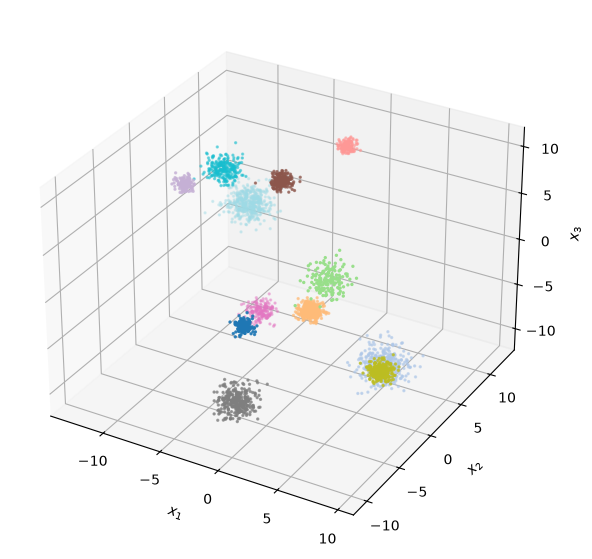

In [6]:
def plot_clusters_3d(X, y=None):
    ax = plt.figure(figsize=(9, 7)).add_subplot(projection='3d')
    ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=y, cmap='tab20', s=2)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("$x_3$")
    return ax

plot_clusters_3d(X, y)
plt.show()

In [7]:
k = len(blob_centers)
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
y_pred = kmeans.fit_predict(X)

print("Centroides encontrados:\n", kmeans.cluster_centers_)
print("\nPuntos por centroide:", np.bincount(y_pred))

Centroides encontrados:
 [[ -1.14235292   9.35494047   8.67929984]
 [  8.3888502   -2.72943771  -4.64673125]
 [-10.02834053   9.67305754  -0.70647743]
 [  0.48680661  -8.97941343   1.24103888]
 [  1.04670803  -0.14938172  -2.60597957]
 [ -2.43467536   1.60142903   8.96077369]
 [  5.97378384   2.37719389  -8.31823813]
 [ -0.81099803  -7.88228131  -8.06031055]
 [ -5.97646254   4.45822748  -8.1963757 ]
 [ -9.64035879   5.27744504   5.74879018]
 [  6.86779149  -8.06079688   7.78139473]
 [ -7.97455902  -3.06109891   9.49571179]]

Puntos por centroide: [158 301 482 160 390 235 336 318 178 238 163 135]


In [8]:
distancias = kmeans.transform(X)
cercanos = {}

for i in range(k):
    idx = np.argsort(distancias[:, i])[:5]
    cercanos[i] = idx

    cx, cy, cz = kmeans.cluster_centers_[i]
    print(f"Centroide {i}: ({cx:.2f}, {cy:.2f}, {cz:.2f})"
          f"  |  puntos en el cluster: {np.sum(y_pred == i)}")
    for j in idx:
        print(f"    punto {j:5d} -> ({X[j, 0]:7.2f}, {X[j, 1]:7.2f}, {X[j, 2]:7.2f})"
              f"   distancia = {distancias[j, i]:.4f}")

Centroide 0: (-1.14, 9.35, 8.68)  |  puntos en el cluster: 158
    punto  1126 -> (  -1.15,    9.42,    8.66)   distancia = 0.0683
    punto  1161 -> (  -1.14,    9.26,    8.60)   distancia = 0.1212
    punto  1100 -> (  -1.21,    9.43,    8.59)   distancia = 0.1333
    punto  1172 -> (  -1.21,    9.27,    8.60)   distancia = 0.1344
    punto  1132 -> (  -1.14,    9.26,    8.58)   distancia = 0.1396
Centroide 1: (8.39, -2.73, -4.65)  |  puntos en el cluster: 301
    punto  2260 -> (   8.35,   -2.78,   -4.55)   distancia = 0.1140
    punto  2105 -> (   8.33,   -2.83,   -4.61)   distancia = 0.1211
    punto  2282 -> (   8.29,   -2.81,   -4.65)   distancia = 0.1292
    punto  2078 -> (   8.44,   -2.62,   -4.58)   distancia = 0.1339
    punto  2312 -> (   8.41,   -2.83,   -4.77)   distancia = 0.1652
Centroide 2: (-10.03, 9.67, -0.71)  |  puntos en el cluster: 482
    punto  2790 -> (  -9.88,    9.60,   -0.56)   distancia = 0.2214
    punto  3030 -> (  -9.98,    9.93,   -0.84)   distancia =

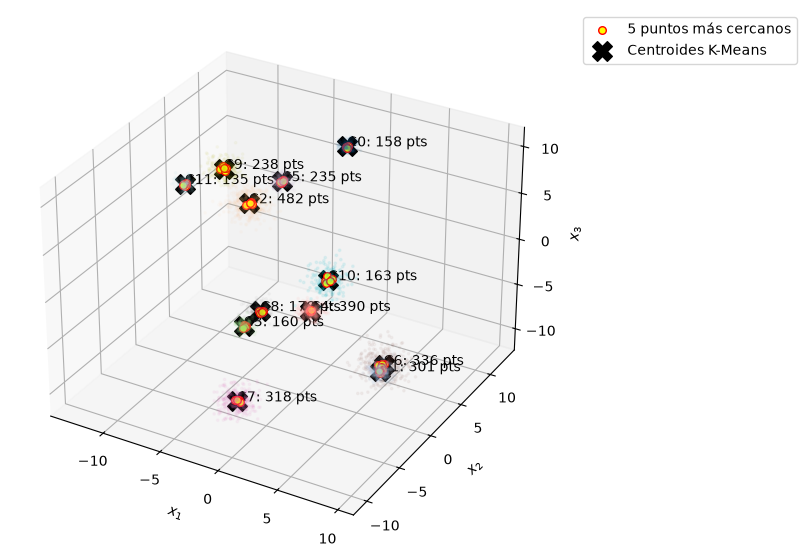

In [9]:
conteo = np.bincount(y_pred, minlength=k)
centros_km = kmeans.cluster_centers_

ax = plt.figure(figsize=(10, 7)).add_subplot(projection='3d')
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=y_pred, cmap='tab20', s=3, alpha=0.3)

idx_cercanos = np.concatenate(list(cercanos.values()))
ax.scatter(X[idx_cercanos, 0], X[idx_cercanos, 1], X[idx_cercanos, 2],
           c='yellow', edgecolors='red', s=30, depthshade=False, label='5 puntos más cercanos')

ax.scatter(centros_km[:, 0], centros_km[:, 1], centros_km[:, 2],
           marker='X', s=200, c='k', depthshade=False, label='Centroides K-Means')

for i in range(k):
    ax.text(centros_km[i, 0], centros_km[i, 1], centros_km[i, 2], f"C{i}: {conteo[i]} pts")

ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("$x_3$")
ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1))
plt.show()

In [11]:
X_new = np.array([[0, 2, 1], [9,9,9], [-3, 3, 0], [-3, 2.5, 2]])
print(kmeans.predict(X_new))
print(kmeans.transform(X_new))

[4 0 4 4]
[[10.6944736  11.16359989 12.74187941 10.99284311  4.32649143  8.33429185
  11.07510408 13.43154604 11.23985377 11.23517564 13.94179    12.70375663]
 [10.15362764 18.00517944 21.37162731 21.35264027 16.78287224 13.61955182
  18.78672183 25.92915927 23.2516121  19.28446931 17.23664997 20.82910202]
 [10.91633486 13.56924746  9.7173236  12.53811565  5.75200666  9.08686183
  12.25192921 13.71803128  8.8411725   9.07357202 16.74110631 12.31469447]
 [ 9.74956963 14.18562526 10.40073772 12.02126345  6.67908056  7.04126353
  13.67515689 14.62167375 10.80092873  8.11554025 15.56689644 10.5762826 ]]
